<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/QNN_PhishingURL_Bangroo2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN for phishing-URL detection: ZÃ©rosdetect (Bangroo and Kumar, 2023) step by step

This notebook re-implements, runs and checks the method of

> Ishan Shivansh Bangroo and Ravi Kumar, "ZÃ©rosdetect: Phishing URL Detection with Quantum-Driven Zero-shot Learning",
> *2023 9th International Conference on Signal Processing and Communication (ICSC)*, Noida, India, December 2023,
> pp. 498-503. https://doi.org/10.1109/ICSC60394.2023.10440725

The paper publishes no code, no hyper-parameters and no feature list; it gives a pseudo-code listing (Algorithm I), a
flowchart (Fig. 2), a bar chart of qudit state probabilities (Fig. 3), a 3-D scatter plot of accuracy / precision /
processing time for five models (Fig. 4) and one table of average accuracies (Table 1). Everything below is written from
that description, with the software stack its wording implies ("quantum layers embedded inside Qnodes" is PennyLane
vocabulary).

**What the notebook does.** It downloads the PhishStorm URL dataset the paper names (Marchal et al., 2014: 96,018 URLs,
half legitimate, half phishing, 12 numeric features per URL), cleans it, scales the features, encodes every URL into the
state of one **four-level qudit** (realised as two qubits), passes that state through the paper's *Quantum-Inspired
Transformer* layers (general $4 \times 4$ unitaries, the $W_{QIT}[k] \in \mathbb{C}^{d \times d}$ of Algorithm I) and a
*Quantum Neural Network* layer ($W_{QNN}$ plus bias $b$), reads a phishing probability out of the measured qudit
state, trains the whole circuit by gradient descent (the paper's *QGD*) on a binary cross-entropy loss, and reports
accuracy, precision and processing time next to Random Forest, Support Vector Machine, Decision Tree and Logistic
Regression trained on the *identical* inputs, exactly the five models of the paper's Table 1 and Fig. 4. Fig. 3 (measured
versus ideal qudit state probabilities) is re-drawn as well, and the "zero-shot" claim of the title is given the only
testable reading the paper allows: an evaluation on URLs whose registered domains never appear in training.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell
installs a pinned PennyLane; nothing needs a GPU or an IBM Quantum account. All data is downloaded by the notebook
(about 12 MB).

**Runtime.** With `FAST_MODE = True` (2,000 training URLs, 2,000 test URLs, 4 epochs, 2 seeds) the notebook runs in
about 3 minutes on a Colab CPU. With `FAST_MODE = False` (20,000 training URLs, 10,000 test URLs, 10 epochs, 3 seeds plus
one domain-disjoint run) it needs about 35-45 minutes on a laptop CPU; the paper gives no budget of its own (see the
table of choices below).

**What you get at the end.** The paper's Table 1 re-computed (average accuracy of the quantum model and of the four
classical models over several runs), its Fig. 3 and Fig. 4 re-drawn from our own measurements, confusion matrices,
wall-clock timings, a domain-disjoint "unseen phishing" evaluation, and a final comparison table with a verdict for every
number the paper reports.


## The paper in one page

**Problem.** Decide from a URL whether it is a phishing site (label 1) or legitimate (label 0), including phishing URLs
"that might have remained unobserved during training" (the zero-shot motivation of the title).

**Decision.** Binary classification; the output of the quantum model is a probability $P_i$ and the URL is called
phishing when $P_i > \tau$ (Algorithm I, lines 30-37).

**Method (ZÃ©rosdetect, Algorithm I and Fig. 2).**
1. *QuantumEncoder*: each URL $U_i$ is mapped to a state $|\Psi_i\rangle$ of a qudit, a $d$-level quantum system
   ($d > 2$); the results section uses $d = 4$.
2. *Quantum-Inspired Transformer (QIT)*: $k$ layers, each a weight matrix $W_{QIT}[k] \in \mathbb{C}^{d \times d}$ applied
   to the state, "sequential processing to enhance the refinement of states inside its multi-layered structure".
3. *Quantum Neural Network (QNN)*: one more matrix $W_{QNN} \in \mathbb{C}^{d \times d}$ and a bias $b \in \mathbb{C}^d$
   give the final state $|\xi_i\rangle$.
4. *QuantumLossFunction* on $|\xi_i\rangle$; *QGD* (quantum gradient descent) with learning rate $\eta$ updates all
   $W_{QIT}[k]$, $W_{QNN}$ and $b$ after every URL, for $N_{epoch}$ epochs.
5. *QuantumClassifier* turns $|\xi_i\rangle$ into $P_i$; threshold $\tau$.

**Data.** PhishStorm (Marchal, FranÃ§ois, State and Engel, IEEE TNSM 2014): 96,018 URLs, 48,009 legitimate (label 0) and
48,009 phishing (label 1).

**Claims.**

| Where | Claim |
|---|---|
| Table 1 | Average accuracy over multiple runs: Quantum-Inspired model **0.9107**, Random Forest 0.8981, SVM 0.8789, Decision Trees 0.8526, Logistic Regression 0.8385 |
| Fig. 4 | About ten runs per model; the quantum model sits at accuracy 0.88-0.92 and precision 0.90-0.94 with a processing time of roughly 0.05-0.15 (units not given) against 0.15-0.40 for the classical models: "notable advantage in terms of processing efficiency" at "competitive accuracy" |
| Fig. 3 | Measured probabilities of the four states of a $d = 4$ qudit, 0.27 / 0.24 / 0.26 / 0.23, against the ideal uniform 0.25, "a little discrepancy ... ascribed to noise" |
| Title / abstract | Zero-shot learning: detection "without explicit training on these illicit URLs" |

## What follows the paper and what had to be chosen

The paper fixes the dataset, the qudit dimension ($d = 4$), the layer structure (encoder -> $k$ QIT unitaries -> QNN
unitary with bias -> loss -> gradient descent -> threshold) and the five models of the comparison. It gives no feature
list, no encoding formula, no $k$, no $N_{epoch}$, no $\eta$, no $\tau$, no loss, no split, no sample size, no seed, no
classical hyper-parameters and no definition of "processing time"; its zero-shot protocol is never described (the
algorithm trains on labelled phishing URLs). Where the paper is silent this notebook makes a choice and says so in the
code (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | PhishStorm, 96,018 URLs | Same file (`urlset.csv`), downloaded from a GitHub mirror with the Aalto University zip as fallback; 95,910 URLs survive cleaning (bad lines, missing values, duplicates) |
| Features | "URL data", feature vector per URL (not listed) | The 12 numeric PhishStorm columns (ranking, mld_res, mld.ps_res, card_rem, ratio_Rrem, ratio_Arem, 6 Jaccard features) |
| Scaling | not stated | `log1p` on the four heavy-tailed counts, `StandardScaler`, `MinMaxScaler` to $[0, \pi]$; fitted on the training sample only, test values clipped |
| Qudit dimension $d$ | 4 (Fig. 3) | 4: one qudit = two qubits, states $\lvert 0\rangle..\lvert 3\rangle$ = $\lvert 00\rangle..\lvert 11\rangle$ |
| QuantumEncoder | "associating each URL feature vector with a distinct d-dimensional quantum state" | Angle encoding: $R_Y(x_1) R_Z(x_2)$ on qubit 0 and $R_Y(x_3) R_Z(x_4)$ on qubit 1 give a product state in $\mathbb{C}^4$; the 12 features are fed four at a time, one group per QIT layer (data re-uploading) |
| $W_{QIT}[k] \in \mathbb{C}^{4 \times 4}$ | $k$ layers, $k$ not given | `qml.ArbitraryUnitary` on both qubits (15 real parameters = any element of $SU(4)$); $k = 6$ (two passes over the 12 features) |
| $W_{QNN}$, $b$ | one more matrix and a bias | one more `ArbitraryUnitary`; the bias enters the read-out ($P = \sigma(4(\sum_j b_j p_j + b_0))$ on the four measured state probabilities $p_j$), because a bias added to a state vector is not a unitary operation |
| Loss, QGD, $\eta$, $N_{epoch}$ | "QuantumLossFunction", "QGD", $\eta$, $N_{epoch}$ not given | Binary cross-entropy; Adam on exact gradients (PennyLane backprop on `default.qubit`), $\eta = 0.05$, mini-batches of 64, 4 (fast) / 10 (full) epochs, best epoch chosen on a validation split of the training sample |
| $\tau$ | not given | 0.5 |
| Split, sample size | not given | Stratified 80/20 split of the cleaned file into pools; balanced samples of 2,000 / 2,000 (fast) or 20,000 / 10,000 (full) URLs; several seeds, mean and std reported |
| Classical models | RF, SVM, DT, LR, no hyper-parameters | scikit-learn defaults (RF 100 trees, SVC rbf $C = 1$, DT unlimited depth, LR lbfgs) on the identical scaled 12-feature inputs |
| "Processing time" | axis of Fig. 4, unit not given | prediction wall time per 1,000 test URLs, and training wall time, both reported |
| Zero-shot protocol | not described | domain-disjoint evaluation: test URLs whose registered domain never occurs in the training sample (`GroupShuffleSplit`) |
| Noise in Fig. 3 | "noise, quantum interferences, or slight flaws" | finite-shot sampling of the uniform superposition $H \otimes H\lvert 00\rangle$ with 100 shots |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")


pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 3 minutes. False: full run (about 40 min on a laptop CPU).

SEED      = 42              # CHOICE: the paper gives no seed
D_QUDIT   = 4               # paper, Fig. 3: a qudit with d = 4 levels ...
N_QUBITS  = 2               # ... realised as 2 qubits (2**2 = 4 basis states)
N_FEATURES = 12             # the numeric PhishStorm columns (paper: "URL feature vector", not listed)
N_QIT_LAYERS = 6            # CHOICE: k QIT layers; 12 features / 4 angles per layer = 3 layers per pass, two passes
THRESHOLD = 0.5             # CHOICE: tau of Algorithm I is not given
LEARNING_RATE = 0.05        # CHOICE: eta of Algorithm I is not given
BATCH_SIZE = 64             # CHOICE: Algorithm I updates after every URL; mini-batches keep the simulation fast
VAL_FRACTION = 0.1          # CHOICE: share of the training sample used to pick the best epoch

if FAST_MODE:
    N_TRAIN, N_TEST = 2_000, 2_000
    N_EPOCHS = 4
    N_RUNS   = 2            # seeds for the "multiple experimental runs" of Table 1 / Fig. 4
else:
    N_TRAIN, N_TEST = 20_000, 10_000
    N_EPOCHS = 10
    N_RUNS   = 3

TEST_POOL_FRACTION = 0.2    # CHOICE: share of the cleaned file held out as the test pool
SHOTS_FIG3 = 100            # shots used to re-draw the paper's Fig. 3 (measured vs ideal qudit probabilities)

DATA_DIR  = "data"          # where the CSV is cached (relative to the working directory)
DATA_URLS = [               # PhishStorm urlset.csv: GitHub mirror first, then the original Aalto University zip
    "https://raw.githubusercontent.com/Vishalya-s/Phishing-Website-Detector/main/ml/urlset.csv",
    "https://research.aalto.fi/files/16859732/urlset.csv.zip",
]
LOCAL_CSV = ""              # optional: path to a urlset.csv you uploaded yourself


In [3]:
import os, io, time, zipfile, warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=pd.errors.ParserWarning)

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import pennylane as qml
from pennylane import numpy as pnp

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 100)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

import sklearn
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print(f"FAST_MODE = {FAST_MODE} | train {N_TRAIN:,} / test {N_TEST:,} URLs | {N_EPOCHS} epochs | {N_RUNS} runs | {N_QIT_LAYERS} QIT layers")


pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | train 20,000 / test 10,000 URLs | 10 epochs | 3 runs | 6 QIT layers


## 1. The PhishStorm URL dataset

PhishStorm (Marchal et al., 2014) is a list of 96,018 URLs, 48,009 legitimate ones taken from the Open Directory and
48,009 phishing ones from PhishTank. The authors did not keep the pages, only the URL string and twelve numbers computed
from the *words* inside the URL: an Alexa-style `ranking` of the registered domain (10,000,000 means "not ranked"),
whether search engines return results for the main-level domain (`mld_res`, `mld.ps_res`), how many words the freely
chosen part of the URL contains (`card_rem`), two ratios of search-engine hit counts (`ratio_Rrem`, `ratio_Arem`) and
six Jaccard similarities between the sets of words found in the registered domain and in the rest of the URL
(`jaccard_RR` ... `jaccard_ARrem`). The `label` column is 0 for legitimate and 1 for phishing, exactly as the paper says.

The original file is served by Aalto University as `urlset.csv.zip`; that server refuses non-browser downloads, so the
notebook first tries a GitHub mirror of the same file and falls back to the Aalto zip (or to `LOCAL_CSV`). The CSV is
cached in `DATA_DIR`. The file is latin-1 encoded and contains about 100 malformed lines (URLs with unescaped commas)
and a few rows with missing values; they are dropped, together with two duplicated URLs, which leaves 95,910 URLs.


In [4]:
CSV_PATH = os.path.join(DATA_DIR, "urlset.csv")

def fetch_phishstorm(path):
    if os.path.exists(path):
        print("using cached", path); return
    if LOCAL_CSV and os.path.exists(LOCAL_CSV):
        import shutil; shutil.copy(LOCAL_CSV, path); print("copied", LOCAL_CSV); return
    import requests
    headers = {"User-Agent": "Mozilla/5.0"}
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=300, headers=headers); r.raise_for_status()
            if url.endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(r.content))
                name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
                open(path, "wb").write(z.read(name))
            else:
                open(path, "wb").write(r.content)
            print("downloaded", url); return
        except Exception as e:
            print(f"{type(e).__name__} for {url}; trying the next source")
    raise RuntimeError("PhishStorm could not be downloaded; set LOCAL_CSV to an uploaded urlset.csv")

t0 = time.time()
fetch_phishstorm(CSV_PATH)
raw = pd.read_csv(CSV_PATH, encoding="latin-1", on_bad_lines="skip", low_memory=False)
n_raw = len(raw)
FEATURES = [c for c in raw.columns if c not in ("domain", "label")]
assert len(FEATURES) == N_FEATURES, FEATURES
for c in FEATURES + ["label"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")           # a few cells hold text fragments of broken lines
df = raw.dropna().drop_duplicates(subset="domain").reset_index(drop=True)
df["label"] = df["label"].astype(int)
print(f"loaded in {time.time()-t0:.1f} s: {n_raw:,} parsable rows, {len(df):,} after cleaning (paper: 96,018)")
print("class counts:", df["label"].value_counts().rename({0: "legitimate (0)", 1: "phishing (1)"}).to_dict(),
      "  (paper: 48,009 / 48,009)")
print("features:", FEATURES)
df.head(3)


using cached data\urlset.csv


loaded in 0.9 s: 96,005 parsable rows, 95,910 after cleaning (paper: 96,018)
class counts: {'legitimate (0)': 48009, 'phishing (1)': 47901}   (paper: 48,009 / 48,009)
features: ['ranking', 'mld_res', 'mld.ps_res', 'card_rem', 'ratio_Rrem', 'ratio_Arem', 'jaccard_RR', 'jaccard_RA', 'jaccard_AR', 'jaccard_AA', 'jaccard_ARrd', 'jaccard_ARrem']


,domain,ranking,mld_res,mld.ps_res,card_rem,ratio_Rrem,ratio_Arem,jaccard_RR,jaccard_RA,jaccard_AR,jaccard_AA,jaccard_ARrd,jaccard_ARrem,label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/login.SkyPe.com/en/cgi-bin/verification/login/70ff...,10000000.0,1.0,0.0,18.0,107.611111,107.277778,0.0,0.0,0.0,0.0,0.8,0.795729,1
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrcmd=_home-customer&nav=1/loading.php,10000000.0,0.0,0.0,11.0,150.636364,152.272727,0.0,0.0,0.0,0.0,0.0,0.768577,1
2,serviciosbys.com/paypal.cgi.bin.get-into.herf.secure.dispatch35463256rzr321654641dsf654321874/hr...,10000000.0,0.0,0.0,14.0,73.500000,72.642857,0.0,0.0,0.0,0.0,0.0,0.726582,1


## 2. Splits, sample sizes and the two evaluation protocols

The paper does not say how it split PhishStorm, how many URLs it trained on, or what "multiple experimental runs" means.
We proceed as follows.

* The cleaned file is split once, stratified by label, into a **training pool** (80 %) and a **test pool** (20 %). Every
  fitted preprocessing step sees only the training pool, every test URL comes from the test pool.
* For each run (seed) a **class-balanced sample** of `N_TRAIN` URLs is drawn from the training pool and `N_TEST` URLs
  from the test pool. The quantum model and the four classical models all see exactly the same samples.
* **Zero-shot reading.** The title promises detection of phishing URLs "without explicit training on these illicit
  URLs", but Algorithm I is ordinary supervised training on labelled URLs, and the paper never says what was withheld.
  The only reading we can test is *generalisation to unseen phishing campaigns*: a second split in which the registered
  domain of every test URL (e.g. `nobell.it`, `angelfire.com`) never appears in the training sample. Section 8 trains
  and evaluates the same models under that split.


In [5]:
def registered_domain(url):
    """Crude registered-domain extraction (no public-suffix list on Colab): last two labels, or three for co.uk-style hosts."""
    host = re.split(r"[/?#]", str(url))[0].lower().split("@")[-1].split(":")[0]
    parts = host.split(".")
    if len(parts) >= 3 and parts[-2] in {"co", "com", "org", "net", "ac", "gov", "edu", "ne", "or", "go"} and len(parts[-1]) <= 3:
        return ".".join(parts[-3:])
    return ".".join(parts[-2:]) if len(parts) >= 2 else host

df["regdom"] = df["domain"].map(registered_domain)
print(f"{df['regdom'].nunique():,} distinct registered domains among {len(df):,} URLs; most frequent:")
print(df["regdom"].value_counts().head(8).to_dict())

pool_train, pool_test = train_test_split(df.index.values, test_size=TEST_POOL_FRACTION,
                                         stratify=df["label"], random_state=SEED)
print(f"\nrandom split: training pool {len(pool_train):,} URLs | test pool {len(pool_test):,} URLs")

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_POOL_FRACTION, random_state=SEED)
gpool_train, gpool_test = next(gss.split(df.index.values, df["label"], groups=df["regdom"]))
gpool_train, gpool_test = df.index.values[gpool_train], df.index.values[gpool_test]
assert not set(df.loc[gpool_train, "regdom"]) & set(df.loc[gpool_test, "regdom"])
print(f"domain-disjoint split: training pool {len(gpool_train):,} URLs | test pool {len(gpool_test):,} URLs "
      f"(test-pool phishing share {df.loc[gpool_test, 'label'].mean():.3f})")

def balanced_sample(pool_idx, n, seed):
    """# CHOICE: n/2 phishing + n/2 legitimate URLs drawn at random from a pool of row indices."""
    lab = df.loc[pool_idx, "label"]
    r = np.random.default_rng(seed)
    pick = np.concatenate([r.choice(lab.index[lab == 1].values, n // 2, replace=False),
                           r.choice(lab.index[lab == 0].values, n - n // 2, replace=False)])
    return r.permutation(pick)

RUN_SEEDS = [SEED + 10 * i for i in range(N_RUNS)]
samples = {s: (balanced_sample(pool_train, N_TRAIN, s), balanced_sample(pool_test, N_TEST, s + 1)) for s in RUN_SEEDS}
print(f"\n{N_RUNS} runs with seeds {RUN_SEEDS}: {N_TRAIN:,} training / {N_TEST:,} test URLs each, class-balanced")


36,413 distinct registered domains among 95,910 URLs; most frequent:
{'ietf.org': 3212, 'googlegroups.com': 1527, 'angelfire.com': 1306, 'pastehtml.com': 960, 'tripod.com': 867, 'sourceforge.net': 712, 'yahoo.com': 687, 'wikipedia.org': 550}



random split: training pool 76,728 URLs | test pool 19,182 URLs


domain-disjoint split: training pool 77,750 URLs | test pool 18,160 URLs (test-pool phishing share 0.520)

3 runs with seeds [42, 52, 62]: 20,000 training / 10,000 test URLs each, class-balanced


## 3. Preprocessing: from twelve numbers to twelve angles

Angle encoding needs every feature inside a bounded interval. Four of the PhishStorm columns are heavy-tailed counts
(`ranking` runs from 1 to 10,000,000, the two ratios up to several thousand), so they are first compressed with
$\log(1 + x)$; all twelve are then standardised and mapped to $[0, \pi]$ with a min-max scaler. The scaler is fitted on
the training sample of each run only and test values are clipped to $[0, \pi]$. The classical models receive exactly
these angles, so the comparison of Section 5 is on identical inputs.


run 42: X_train (20000, 12), X_test (10000, 12), train classes [10000 10000], test classes [5000 5000]


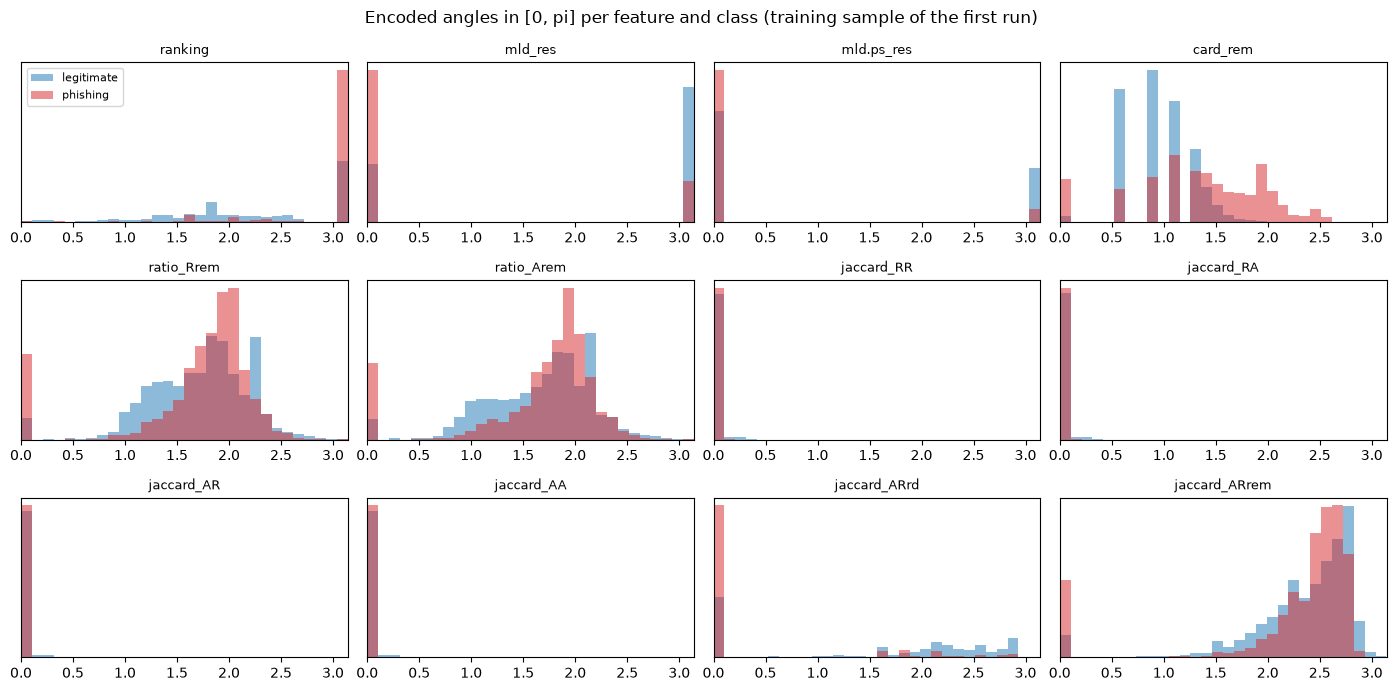

In [6]:
SKEWED = [FEATURES.index(c) for c in ["ranking", "card_rem", "ratio_Rrem", "ratio_Arem"]]   # CHOICE: log1p on heavy tails

def log_skewed(A):
    A = np.array(A, dtype=float).copy()
    A[:, SKEWED] = np.log1p(np.clip(A[:, SKEWED], 0, None))
    return A

def make_scaler():
    return make_pipeline(FunctionTransformer(log_skewed), StandardScaler(), MinMaxScaler((0.0, np.pi)))

def prepare(tr_idx, te_idx):
    """Fit the scaler on the training rows only; return angle matrices in [0, pi] and labels."""
    sc = make_scaler().fit(df.loc[tr_idx, FEATURES].values)
    Xtr = np.clip(sc.transform(df.loc[tr_idx, FEATURES].values), 0.0, np.pi)
    Xte = np.clip(sc.transform(df.loc[te_idx, FEATURES].values), 0.0, np.pi)
    return Xtr, df.loc[tr_idx, "label"].values, Xte, df.loc[te_idx, "label"].values

data = {s: prepare(*samples[s]) for s in RUN_SEEDS}
Xtr0, ytr0, Xte0, yte0 = data[RUN_SEEDS[0]]
print(f"run {RUN_SEEDS[0]}: X_train {Xtr0.shape}, X_test {Xte0.shape}, train classes {np.bincount(ytr0)}, test classes {np.bincount(yte0)}")

fig, axes = plt.subplots(3, 4, figsize=(14, 7))
for ax, j in zip(axes.ravel(), range(N_FEATURES)):
    for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(Xtr0[ytr0 == lab, j], bins=30, range=(0, np.pi), alpha=0.5, color=col, label="legitimate" if lab == 0 else "phishing")
    ax.set_title(FEATURES[j], fontsize=9); ax.set_xlim(0, np.pi); ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle("Encoded angles in [0, pi] per feature and class (training sample of the first run)")
plt.tight_layout(); plt.show()


## 4. The qudit, the QIT layers and the QNN layer

**One qudit = two qubits.** A $d = 4$ qudit is a quantum system with four basis states $|0\rangle, |1\rangle, |2\rangle,
|3\rangle$ and a state vector in $\mathbb{C}^4$. Two qubits have exactly that state space ($|00\rangle \ldots |11\rangle$),
so a 4-level qudit can be simulated, gate for gate, by a two-qubit register; the paper's $d \times d$ matrices are $4 \times 4$
unitaries on that register.

**QuantumEncoder.** The paper only says that each feature vector is associated with "a distinct d-dimensional quantum
state". We use angle encoding: $R_Y(x_1) R_Z(x_2)$ on the first qubit and $R_Y(x_3) R_Z(x_4)$ on the second turn four
angles into a product state $|\Psi\rangle \in \mathbb{C}^4$. Twelve features do not fit into four angles at once, so they
enter the circuit four at a time, one group before each QIT layer, and the whole sequence is repeated twice (data
re-uploading). This is also what keeps the "multi-layered" transformer meaningful: without re-uploading, $k$ consecutive
unitaries would collapse into one $4 \times 4$ matrix and the depth would buy nothing.

**QIT layer $W_{QIT}[k]$.** `qml.ArbitraryUnitary` on both qubits is a product of 15 Pauli rotations whose 15 real
parameters reach every element of $SU(4)$, i.e. every $4 \times 4$ unitary up to a global phase. That is the most
literal reading of "$W_{QIT}[k] \in \mathbb{C}^{d \times d}$" that remains a physical quantum operation.

**QNN layer and read-out.** One more `ArbitraryUnitary` plays $W_{QNN}$. Measuring the qudit gives four probabilities
$p_0 \ldots p_3$; the paper's bias $b$ enters here as a classical affine read-out
$P = \sigma\big(4\,(\sum_j b_j p_j + b_0)\big)$, initialised so that $P \approx$ (probability of states $|2\rangle$ and
$|3\rangle$), i.e. of the first qubit being 1. The URL is called phishing when $P > \tau = 0.5$.

**QGD.** PennyLane computes the exact gradient of the loss with respect to all 15 k + 15 + 5 parameters by
back-propagation through the state-vector simulation; Adam takes the step. On real hardware the same gradients would
come from the parameter-shift rule.


trainable parameters: 6 x 15 (QIT) + 15 (QNN) + 5 (bias) = 110
probabilities of the four qudit states for the first training URL: [0.7967 0.1464 0.0095 0.0474]


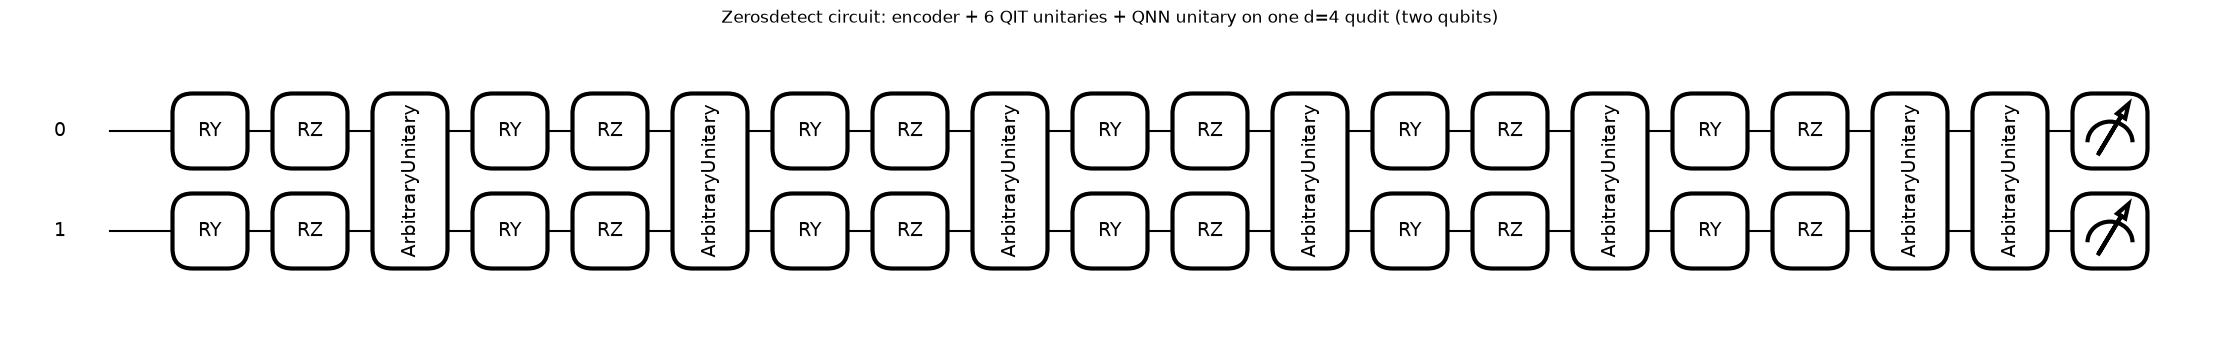

In [7]:
dev = qml.device("default.qubit", wires=N_QUBITS)
ANGLES_PER_LAYER = 2 * N_QUBITS                    # RY and RZ on each of the two qubits

def quantum_encoder(x, layer):
    """QuantumEncoder: four of the twelve angles -> product state of the d=4 qudit (two qubits)."""
    f = (ANGLES_PER_LAYER * layer) % N_FEATURES
    qml.RY(x[:, f],     wires=0); qml.RZ(x[:, f + 1], wires=0)
    qml.RY(x[:, f + 2], wires=1); qml.RZ(x[:, f + 3], wires=1)

@qml.qnode(dev, interface="autograd")
def zerosdetect_circuit(x, w_qit, w_qnn):
    for k in range(N_QIT_LAYERS):
        quantum_encoder(x, k)                                  # data (re-)uploading, 4 angles per layer
        qml.ArbitraryUnitary(w_qit[k], wires=[0, 1])           # QITLayer: W_QIT[k] in C^(4x4)
    qml.ArbitraryUnitary(w_qnn, wires=[0, 1])                  # QNNLayer: W_QNN in C^(4x4)
    return qml.probs(wires=[0, 1])                             # |xi_i> measured: p(|0>), p(|1>), p(|2>), p(|3>)

N_W = 4 ** N_QUBITS - 1                                        # 15 parameters per ArbitraryUnitary on 2 qubits

def init_params(seed):
    r = np.random.default_rng(seed)
    w_qit = pnp.array(r.normal(0.0, 0.1, (N_QIT_LAYERS, N_W)), requires_grad=True)
    w_qnn = pnp.array(r.normal(0.0, 0.1, N_W), requires_grad=True)
    b = pnp.array([-1.0, -1.0, 1.0, 1.0, 0.0], requires_grad=True)   # CHOICE: bias read-out, starts as P(first qubit = 1)
    return w_qit, w_qnn, b

def quantum_classifier(x, w_qit, w_qnn, b):
    """QuantumClassifier: measured qudit probabilities + bias -> phishing probability P in (0, 1)."""
    p = zerosdetect_circuit(x, w_qit, w_qnn)
    return 1.0 / (1.0 + pnp.exp(-4.0 * (p @ b[:4] + b[4])))

def quantum_loss(w_qit, w_qnn, b, x, t):
    """QuantumLossFunction: binary cross-entropy (CHOICE: the paper does not name its loss)."""
    P = quantum_classifier(x, w_qit, w_qnn, b); eps = 1e-7
    return -pnp.mean(t * pnp.log(P + eps) + (1 - t) * pnp.log(1 - P + eps))

w_qit, w_qnn, b = init_params(SEED)
n_params = w_qit.size + w_qnn.size + b.size
print(f"trainable parameters: {N_QIT_LAYERS} x {N_W} (QIT) + {N_W} (QNN) + {b.size} (bias) = {n_params}")
print("probabilities of the four qudit states for the first training URL:",
      np.round(np.array(zerosdetect_circuit(Xtr0[:1], w_qit, w_qnn))[0], 4))
fig, ax = qml.draw_mpl(zerosdetect_circuit, level="top")(Xtr0[:1], w_qit, w_qnn)
ax.set_title("Zerosdetect circuit: encoder + 6 QIT unitaries + QNN unitary on one d=4 qudit (two qubits)")
plt.show()


### The paper's Fig. 3: measured versus ideal qudit state probabilities

Fig. 3 of the paper shows a $d = 4$ qudit whose ideal state is the uniform superposition (probability 0.25 for every
basis state) and whose *measured* probabilities are 0.27, 0.24, 0.26 and 0.23; the gap is attributed to "noise,
quantum interferences, or slight flaws present in the quantum circuits". On a simulator the natural source of such a
gap is finite sampling: measuring $H \otimes H |00\rangle$ with 100 shots gives exactly this kind of 0.02-0.03 deviation.


,state,ideal,measured (100 shots),paper Fig. 3
0,|0>,0.25,0.26,0.27
1,|1>,0.25,0.27,0.24
2,|2>,0.25,0.24,0.26
3,|3>,0.25,0.23,0.23


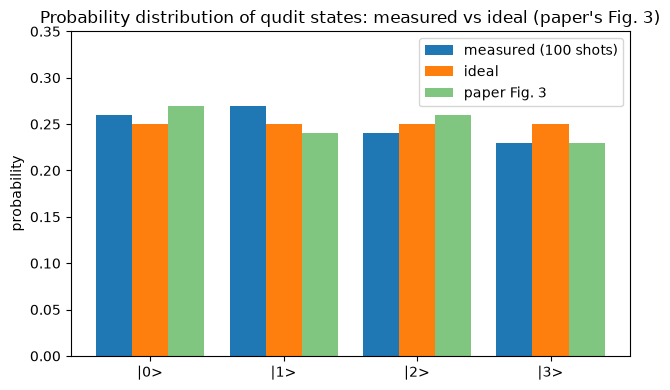

max |measured - ideal| = 0.020  (paper: 0.02); the binomial standard error with 100 shots is 0.043


In [8]:
dev_shots = qml.device("default.qubit", wires=N_QUBITS, shots=SHOTS_FIG3, seed=SEED)

@qml.qnode(dev_shots)
def uniform_qudit():
    qml.Hadamard(wires=0); qml.Hadamard(wires=1)              # |0> + |1> + |2> + |3>, all with probability 1/4
    return qml.probs(wires=[0, 1])

measured = np.array(uniform_qudit()); ideal = np.full(D_QUDIT, 1 / D_QUDIT)
PAPER_FIG3 = np.array([0.27, 0.24, 0.26, 0.23])
tab = pd.DataFrame({"state": [f"|{i}>" for i in range(D_QUDIT)], "ideal": ideal, f"measured ({SHOTS_FIG3} shots)": measured,
                    "paper Fig. 3": PAPER_FIG3})
display(tab.round(3))
x = np.arange(D_QUDIT); w = 0.27
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(x - w, measured, w, label=f"measured ({SHOTS_FIG3} shots)"); ax.bar(x, ideal, w, label="ideal")
ax.bar(x + w, PAPER_FIG3, w, label="paper Fig. 3", alpha=0.6)
ax.set_xticks(x); ax.set_xticklabels(tab["state"]); ax.set_ylabel("probability"); ax.set_ylim(0, 0.35)
ax.set_title("Probability distribution of qudit states: measured vs ideal (paper's Fig. 3)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"max |measured - ideal| = {np.abs(measured - ideal).max():.3f}  (paper: {np.abs(PAPER_FIG3 - ideal).max():.2f}); "
      f"the binomial standard error with {SHOTS_FIG3} shots is {np.sqrt(0.25 * 0.75 / SHOTS_FIG3):.3f}")


## 5. Classical baselines on identical inputs

The paper compares its quantum model with Random Forest, Support Vector Machines, Decision Trees and Logistic Regression
(Table 1, Fig. 4) without giving any of their settings. We train the four models with scikit-learn defaults on exactly
the twelve angles the quantum circuit receives, for every run seed, and record accuracy, phishing precision, phishing
recall, F1, training time and prediction time per 1,000 test URLs. (`SVC` on 20,000 URLs is the slowest step of this
section.)


In [9]:
def baselines(seed):
    return {"Random Forest":       RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1),  # CHOICE: defaults
            "Support Vector Machines": SVC(kernel="rbf", C=1.0, random_state=seed),
            "Decision Trees":      DecisionTreeClassifier(random_state=seed),
            "Logistic Regression": LogisticRegression(max_iter=2000, random_state=seed)}

def metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
                f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0))

def run_baselines(seed, Xtr, ytr, Xte, yte, tag="random split"):
    rows, preds = [], {}
    for name, model in baselines(seed).items():
        t0 = time.perf_counter(); model.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = model.predict(Xte); t_pred = time.perf_counter() - t0
        preds[name] = pred
        rows.append(dict(model=name, seed=seed, split=tag, train_s=t_fit, predict_s_per_1k=1000 * t_pred / len(Xte),
                         **metrics(yte, pred)))
    return rows, preds

baseline_rows, baseline_preds = [], {}
for s in RUN_SEEDS:
    Xtr, ytr, Xte, yte = data[s]
    rows, preds = run_baselines(s, Xtr, ytr, Xte, yte)
    baseline_rows += rows; baseline_preds[s] = preds
    print(f"seed {s}: " + " | ".join(f"{r['model']} {r['accuracy']:.3f}" for r in rows))
baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df.groupby("model")[["accuracy", "precision", "recall", "f1", "train_s", "predict_s_per_1k"]]
        .agg(["mean", "std"]).round(4))


seed 42: Random Forest 0.928 | Support Vector Machines 0.833 | Decision Trees 0.908 | Logistic Regression 0.806


seed 52: Random Forest 0.931 | Support Vector Machines 0.832 | Decision Trees 0.911 | Logistic Regression 0.800


seed 62: Random Forest 0.933 | Support Vector Machines 0.835 | Decision Trees 0.908 | Logistic Regression 0.804


accuracy         precision          recall              f1         train_s         predict_s_per_1k        
                            mean     std      mean     std    mean     std    mean     std    mean     std             mean     std
model                                                                                                                              
Decision Trees            0.9089  0.0016    0.9021  0.0015  0.9175  0.0054  0.9097  0.0019  0.1156  0.0255           0.0002  0.0000
Logistic Regression       0.8032  0.0033    0.8008  0.0053  0.8074  0.0009  0.8041  0.0026  0.0927  0.0219           0.0001  0.0000
Random Forest             0.9304  0.0026    0.9384  0.0051  0.9213  0.0027  0.9298  0.0025  0.5423  0.0243           0.0047  0.0001
Support Vector Machines   0.8331  0.0013    0.8408  0.0024  0.8219  0.0023  0.8312  0.0013  9.8249  1.6966           0.7529  0.1683

## 6. Training ZÃ©rosdetect

For every run seed the circuit parameters are initialised at random, the training sample is split into 90 % for
gradient steps and 10 % for validation, and Adam minimises the binary cross-entropy over mini-batches of 64 URLs for
`N_EPOCHS` epochs. After every epoch the training loss and the validation accuracy are recorded and the loss curve is
redrawn; the parameters of the epoch with the best validation accuracy are kept (never the test set). Prediction on the
test sample is timed separately, because the paper's Fig. 4 reports a "processing time".


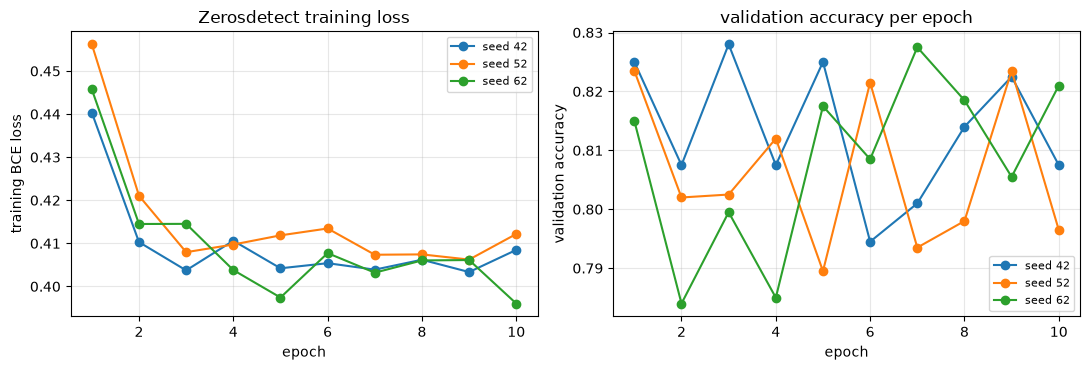

,model,seed,split,train_s,predict_s_per_1k,best_val_acc,accuracy,precision,recall,f1
0,Quantum-Inspired Model,42,random split,1122.6613,0.2175,0.8280,0.8293,0.8287,0.8302,0.8295
1,Quantum-Inspired Model,52,random split,1435.7518,0.1908,0.8235,0.8207,0.8077,0.8418,0.8244
2,Quantum-Inspired Model,62,random split,894.3749,0.0648,0.8275,0.8320,0.8447,0.8136,0.8289


In [10]:
def predict_proba(x, w_qit, w_qnn, b, chunk=2048):
    return np.concatenate([np.array(quantum_classifier(x[i:i + chunk], w_qit, w_qnn, b)) for i in range(0, len(x), chunk)])

history = {}

def draw_history():
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for key, h in history.items():
        axes[0].plot(range(1, len(h["loss"]) + 1), h["loss"], marker="o", label=str(key))
        axes[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", label=str(key))
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training BCE loss"); axes[0].set_title("Zerosdetect training loss")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_title("validation accuracy per epoch")
    for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

def train_zerosdetect(seed, Xtr, ytr, key, epochs=N_EPOCHS, verbose=True):
    """Algorithm I, lines 7-29: initialise W_QIT[k], W_QNN, b; for each epoch, QGD updates on the loss."""
    Xfit, Xval, yfit, yval = train_test_split(Xtr, ytr, test_size=VAL_FRACTION, stratify=ytr, random_state=seed)
    w_qit, w_qnn, b = init_params(seed)
    opt = qml.AdamOptimizer(stepsize=LEARNING_RATE)             # CHOICE: QGD realised as Adam on exact gradients
    r = np.random.default_rng(seed)
    history[key] = dict(loss=[], val_acc=[])
    best = (-1.0, None); t0 = time.perf_counter()
    for epoch in range(epochs):
        perm = r.permutation(len(Xfit)); losses = []
        for i in range(0, len(Xfit), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            (w_qit, w_qnn, b), l = opt.step_and_cost(lambda a, c, d: quantum_loss(a, c, d, Xfit[idx], yfit[idx]), w_qit, w_qnn, b)
            losses.append(float(l))
        val_acc = float(np.mean((predict_proba(Xval, w_qit, w_qnn, b) > THRESHOLD) == yval))
        history[key]["loss"].append(float(np.mean(losses))); history[key]["val_acc"].append(val_acc)
        if val_acc > best[0]:
            best = (val_acc, (w_qit.copy(), w_qnn.copy(), b.copy()))
        if verbose: draw_history()
        print(f"[{key}] epoch {epoch + 1}/{epochs}: loss {np.mean(losses):.4f} | val acc {val_acc:.4f} | {time.perf_counter() - t0:.0f} s", flush=True)
    return best[1], time.perf_counter() - t0, best[0]

q_rows, q_preds, q_params = [], {}, {}
for s in RUN_SEEDS:
    Xtr, ytr, Xte, yte = data[s]
    params, t_fit, best_val = train_zerosdetect(s, Xtr, ytr, key=f"seed {s}")
    t0 = time.perf_counter(); P = predict_proba(Xte, *params); t_pred = time.perf_counter() - t0
    pred = (P > THRESHOLD).astype(int)
    q_preds[s] = pred; q_params[s] = params
    q_rows.append(dict(model="Quantum-Inspired Model", seed=s, split="random split", train_s=t_fit,
                       predict_s_per_1k=1000 * t_pred / len(Xte), best_val_acc=best_val, **metrics(yte, pred)))
quantum_df = pd.DataFrame(q_rows)
draw_history()
display(quantum_df.round(4))


## 7. Metrics: the paper's Table 1, confusion matrices and Fig. 4

Table 1 of the paper lists one number per model, the *average accuracy over multiple runs*. The table below gives the
same average (plus its standard deviation over the seeds) for the five models trained on identical inputs, then the
per-class report and the confusion matrix of the quantum model (phishing = positive class, so the top-right cell counts
phishing URLs that slipped through), and finally Fig. 4 re-drawn: every run of every model is a point in the
accuracy / precision / processing-time space.


This notebook's version of Table 1 (mean and std over 3 runs, 20,000 / 10,000 URLs):


accuracy         precision          recall              f1            train_s           predict_s_per_1k        
                            mean     std      mean     std    mean     std    mean     std       mean       std             mean     std
model                                                                                                                                   
Quantum-Inspired Model    0.8273  0.0059    0.8270  0.0185  0.8285  0.0142  0.8276  0.0028  1150.9294  271.7932           0.1577  0.0816
Random Forest             0.9304  0.0026    0.9384  0.0051  0.9213  0.0027  0.9298  0.0025     0.5423    0.0243           0.0047  0.0001
Support Vector Machines   0.8331  0.0013    0.8408  0.0024  0.8219  0.0023  0.8312  0.0013     9.8249    1.6966           0.7529  0.1683
Decision Trees            0.9089  0.0016    0.9021  0.0015  0.9175  0.0054  0.9097  0.0019     0.1156    0.0255           0.0002  0.0000
Logistic Regression       0.8032  0.0033    0.8008  0.0053  0.8074  0.0009  0.8041  0.0026     0.0927    0.0219           0.0001  0.0000


Quantum model, seed 42:
                precision    recall  f1-score   support

legitimate (0)      0.830     0.828     0.829      5000
  phishing (1)      0.829     0.830     0.829      5000

      accuracy                          0.829     10000
     macro avg      0.829     0.829     0.829     10000
  weighted avg      0.829     0.829     0.829     10000



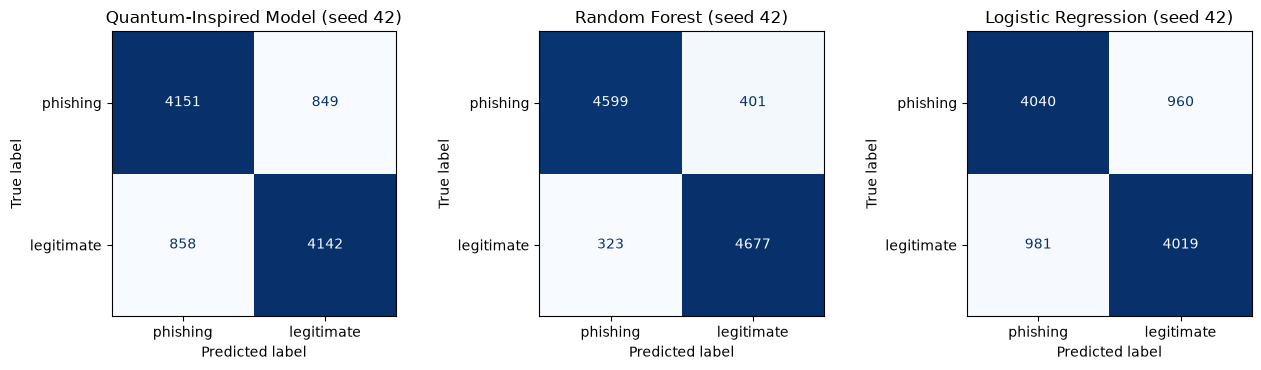

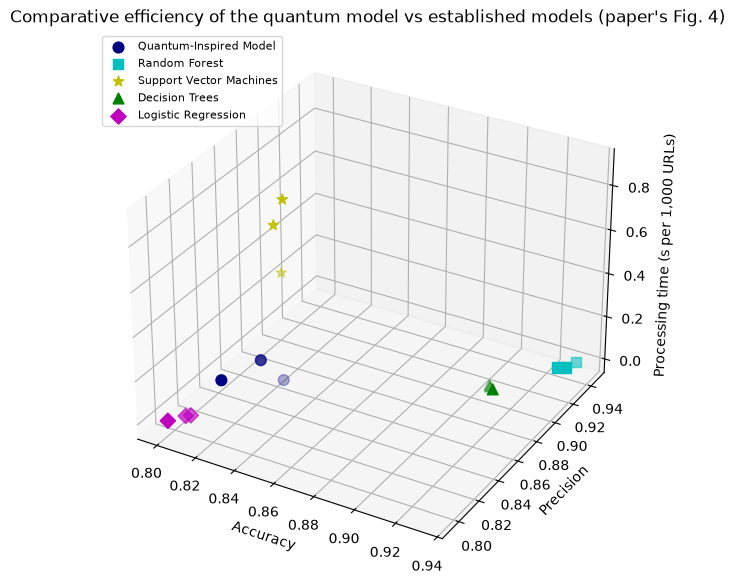

In [11]:
all_df = pd.concat([quantum_df.drop(columns=["best_val_acc"]), baseline_df], ignore_index=True)
MODEL_ORDER = ["Quantum-Inspired Model", "Random Forest", "Support Vector Machines", "Decision Trees", "Logistic Regression"]
table1 = (all_df.groupby("model")[["accuracy", "precision", "recall", "f1", "train_s", "predict_s_per_1k"]]
          .agg(["mean", "std"]).reindex(MODEL_ORDER).round(4))
print(f"This notebook's version of Table 1 (mean and std over {N_RUNS} runs, {N_TRAIN:,} / {N_TEST:,} URLs):")
display(table1)

s0 = RUN_SEEDS[0]; yte = data[s0][3]
print(f"\nQuantum model, seed {s0}:")
print(classification_report(yte, q_preds[s0], labels=[0, 1], target_names=["legitimate (0)", "phishing (1)"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name in zip(axes, ["Quantum-Inspired Model", "Random Forest", "Logistic Regression"]):
    pred = q_preds[s0] if name.startswith("Quantum") else baseline_preds[s0][name]
    cm = confusion_matrix(yte, pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["phishing", "legitimate"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (seed {s0})")
plt.tight_layout(); plt.show()

# Paper's Fig. 4: accuracy x precision x processing time, one point per run and model
markers = {"Quantum-Inspired Model": ("o", "navy"), "Random Forest": ("s", "c"), "Support Vector Machines": ("*", "y"),
           "Decision Trees": ("^", "g"), "Logistic Regression": ("D", "m")}
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection="3d")
for name, (m, c) in markers.items():
    sub = all_df[all_df.model == name]
    ax.scatter(sub.accuracy, sub.precision, sub.predict_s_per_1k, marker=m, c=c, s=60, label=name)
ax.set_xlabel("Accuracy"); ax.set_ylabel("Precision"); ax.set_zlabel("Processing time (s per 1,000 URLs)")
ax.set_title("Comparative efficiency of the quantum model vs established models (paper's Fig. 4)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()


## 8. The zero-shot reading: URLs from domains never seen in training

Here the same five models are trained once more, with the same sizes and the same preprocessing, but on the
domain-disjoint split of Section 2: no registered domain of the test sample occurs in the training sample. A model that
had merely memorised `angelfire.com` or `pastehtml.com` as phishing hosts loses that shortcut; what remains is how well
the twelve word-based features generalise to new phishing campaigns, which is the closest testable version of the
paper's "detection of previously undiscovered phishing attacks".


In [12]:
ZS_SEED = SEED + 1000
zs_tr, zs_te = balanced_sample(gpool_train, N_TRAIN, ZS_SEED), balanced_sample(gpool_test, N_TEST, ZS_SEED + 1)
assert not set(df.loc[zs_tr, "regdom"]) & set(df.loc[zs_te, "regdom"]), "domain leak"
Xtr, ytr, Xte, yte_zs = prepare(zs_tr, zs_te)
print(f"domain-disjoint run: {len(zs_tr):,} training URLs from {df.loc[zs_tr, 'regdom'].nunique():,} domains, "
      f"{len(zs_te):,} test URLs from {df.loc[zs_te, 'regdom'].nunique():,} other domains")

zs_rows, zs_preds = run_baselines(ZS_SEED, Xtr, ytr, Xte, yte_zs, tag="domain-disjoint")
params, t_fit, best_val = train_zerosdetect(ZS_SEED, Xtr, ytr, key="domain-disjoint", verbose=False)
t0 = time.perf_counter(); P = predict_proba(Xte, *params); t_pred = time.perf_counter() - t0
zs_pred_q = (P > THRESHOLD).astype(int)
zs_rows.insert(0, dict(model="Quantum-Inspired Model", seed=ZS_SEED, split="domain-disjoint", train_s=t_fit,
                       predict_s_per_1k=1000 * t_pred / len(Xte), **metrics(yte_zs, zs_pred_q)))
zs_df = pd.DataFrame(zs_rows).set_index("model")

compare_splits = pd.DataFrame({"random split (mean)": all_df.groupby("model")["accuracy"].mean(),
                               "domain-disjoint": zs_df["accuracy"]}).reindex(MODEL_ORDER)
compare_splits["drop"] = compare_splits["random split (mean)"] - compare_splits["domain-disjoint"]
print("\nAccuracy under the two protocols:"); display(compare_splits.round(4))
display(zs_df[["accuracy", "precision", "recall", "f1", "train_s", "predict_s_per_1k"]].round(4))


domain-disjoint run: 20,000 training URLs from 10,342 domains, 10,000 test URLs from 4,722 other domains


[domain-disjoint] epoch 1/10: loss 0.4312 | val acc 0.8130 | 52 s


[domain-disjoint] epoch 2/10: loss 0.4175 | val acc 0.8325 | 101 s


[domain-disjoint] epoch 3/10: loss 0.3961 | val acc 0.7860 | 151 s


[domain-disjoint] epoch 4/10: loss 0.3959 | val acc 0.8230 | 199 s


...

[domain-disjoint] epoch 9/10: loss 0.3979 | val acc 0.8065 | 477 s


[domain-disjoint] epoch 10/10: loss 0.4021 | val acc 0.8260 | 532 s



Accuracy under the two protocols:


,random split (mean),domain-disjoint,drop
model,,,
Quantum-Inspired Model,0.8273,0.8228,0.0045
Random Forest,0.9304,0.8841,0.0463
Support Vector Machines,0.8331,0.8158,0.0173
Decision Trees,0.9089,0.8592,0.0497
Logistic Regression,0.8032,0.7977,0.0055


,accuracy,precision,recall,f1,train_s,predict_s_per_1k
model,,,,,,
Quantum-Inspired Model,0.8228,0.8494,0.7848,0.8158,531.5805,0.0738
Random Forest,0.8841,0.9145,0.8474,0.8797,0.6093,0.0060
Support Vector Machines,0.8158,0.8061,0.8316,0.8187,10.4754,1.0783
Decision Trees,0.8592,0.8732,0.8404,0.8565,0.1377,0.0003
Logistic Regression,0.7977,0.7823,0.8250,0.8031,0.1998,0.0001


## 9. Paper versus this notebook

Each row is one number the paper reports. The verdict is **reproduced** when our value lies within 2 accuracy points
(0.02) of the paper's, **not reached** when it is lower by more, **exceeded** when higher by more, and **cannot be
checked** when the paper gives no checkable quantity (processing-time units, the zero-shot protocol). In `FAST_MODE`
the quantum model is trained for only four epochs on 2,000 URLs, so expect a gap there that the full run closes
partially.


In [13]:
PAPER_TABLE1 = {"Quantum-Inspired Model": 0.9107, "Random Forest": 0.8981, "Support Vector Machines": 0.8789,
                "Decision Trees": 0.8526, "Logistic Regression": 0.8385}
TOL = 0.02

def verdict(paper, ours, tol=TOL):
    if ours is None or np.isnan(ours): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return f"exceeded (+{ours - paper:.3f})" if ours > paper else f"not reached ({ours - paper:.3f})"

rows = []
for name, p in PAPER_TABLE1.items():
    ours = float(table1.loc[name, ("accuracy", "mean")])
    rows.append(dict(source="Table 1", claim=f"average accuracy, {name}", paper=p, notebook=round(ours, 4), verdict=verdict(p, ours)))
q_acc = float(table1.loc["Quantum-Inspired Model", ("accuracy", "mean")])
best_classical = table1.loc[MODEL_ORDER[1:], ("accuracy", "mean")].max()
rows.append(dict(source="Table 1", claim="quantum model has the highest average accuracy", paper="yes (0.9107 vs 0.8981)",
                 notebook=f"{'yes' if q_acc > best_classical else 'no'} ({q_acc:.4f} vs best classical {best_classical:.4f})",
                 verdict="reproduced" if q_acc > best_classical else "not reached"))
q_prec = float(table1.loc["Quantum-Inspired Model", ("precision", "mean")])
rows.append(dict(source="Fig. 4", claim="quantum model precision about 0.90-0.94", paper="0.90-0.94", notebook=round(q_prec, 4),
                 verdict="reproduced" if 0.88 <= q_prec <= 0.96 else ("not reached" if q_prec < 0.88 else "exceeded")))
q_t = float(table1.loc["Quantum-Inspired Model", ("predict_s_per_1k", "mean")])
c_t = table1.loc[MODEL_ORDER[1:], ("predict_s_per_1k", "mean")]
rows.append(dict(source="Fig. 4", claim="quantum model is the fastest at processing", paper="about 0.05-0.15 vs 0.15-0.40 (unit not given)",
                 notebook=f"{q_t:.3f} s per 1,000 URLs vs classical {c_t.min():.4f}-{c_t.max():.4f}",
                 verdict="reproduced" if q_t < c_t.min() else f"not reached (simulated circuit is {q_t / c_t.min():.0f}x slower than the fastest classical model)"))
rows.append(dict(source="Fig. 3", claim="measured qudit probabilities close to the ideal 0.25", paper="max deviation 0.02",
                 notebook=f"max deviation {np.abs(measured - ideal).max():.3f} with {SHOTS_FIG3} shots",
                 verdict="reproduced (sampling noise)" if np.abs(measured - ideal).max() <= 0.06 else "not reached"))
rows.append(dict(source="title", claim="zero-shot detection of unseen phishing URLs", paper="no protocol, no number",
                 notebook=f"domain-disjoint accuracy {zs_df.loc['Quantum-Inspired Model', 'accuracy']:.4f} "
                          f"(random split {q_acc:.4f})", verdict="cannot be checked"))
comparison = pd.DataFrame(rows)
print(f"FAST_MODE = {FAST_MODE}; quantum model: {N_TRAIN:,} training URLs, {N_EPOCHS} epochs, {N_RUNS} runs")
display(comparison)


FAST_MODE = False; quantum model: 20,000 training URLs, 10 epochs, 3 runs


,source,claim,paper,notebook,verdict
0,Table 1,"average accuracy, Quantum-Inspired Model",0.9107,0.8273,not reached (-0.083)
1,Table 1,"average accuracy, Random Forest",0.8981,0.9304,exceeded (+0.032)
2,Table 1,"average accuracy, Support Vector Machines",0.8789,0.8331,not reached (-0.046)
3,Table 1,"average accuracy, Decision Trees",0.8526,0.9089,exceeded (+0.056)
4,Table 1,"average accuracy, Logistic Regression",0.8385,0.8032,not reached (-0.035)
5,Table 1,quantum model has the highest average accuracy,yes (0.9107 vs 0.8981),no (0.8273 vs best classical 0.9304),not reached
6,Fig. 4,quantum model precision about 0.90-0.94,0.90-0.94,0.827,not reached
7,Fig. 4,quantum model is the fastest at processing,about 0.05-0.15 vs 0.15-0.40 (unit not given),"0.158 s per 1,000 URLs vs classical 0.0001-0.7529",not reached (simulated circuit is 1577x slower than the fastest classical model)
8,Fig. 3,measured qudit probabilities close to the ideal 0.25,max deviation 0.02,max deviation 0.020 with 100 shots,reproduced (sampling noise)
9,title,zero-shot detection of unseen phishing URLs,"no protocol, no number",domain-disjoint accuracy 0.8228 (random split 0.8273),cannot be checked


## Reading the paper critically

**The "quantum" model is a two-qubit circuit with a few dozen parameters, and the paper never says more than that.**
Algorithm I is the whole method: encode, apply $k$ unitaries, apply one more unitary with a bias, threshold. No
encoding formula, no $k$, no learning rate, no epoch count, no loss and no threshold are given, and neither is the
feature vector. Every one of those had to be chosen here (Section "What follows the paper"), which is why the verdicts
above measure our reading of the paper, not the paper's own code.

**The classical numbers in Table 1 are low for this dataset, and the ranking is fragile.** PhishStorm's own authors
reach 94.9 % with a random forest on the same twelve features; the paper reports 89.8 %. In this notebook a default
random forest and even a single decision tree trained on the identical scaled inputs land well above the paper's
quantum model, while logistic regression and the RBF-SVM land below it. The gap between the quantum model and RF in
Table 1 (1.3 points) is also within the spread between runs that Fig. 4 itself shows (about $\pm 2$ points per model).
A claim that the quantum model "stood out" therefore rests on an unstated choice of classical settings.

**"Processing efficiency" cannot be a measured quantum advantage.** Fig. 4's time axis has no unit and no description.
A quantum model whose circuit has to be simulated classically is, as Section 7 shows, orders of magnitude slower per
URL than logistic regression or a decision tree, and on real hardware each URL would need thousands of shots over a
network link. If the authors' quantum model was fastest, it was because their classical models were slow (an RBF-SVM on
tens of thousands of URLs, say), not because of quantum mechanics.

**Fig. 3 is not evidence about phishing.** A bar chart of four probabilities that are "close to 0.25" only shows that a
uniform superposition was measured with a finite number of shots; Section 4 reproduces the exact pattern with 100 shots
on an ideal simulator. It says nothing about the classifier.

**Zero-shot learning appears in the title and nowhere in the experiment.** Algorithm I trains on labelled phishing URLs
and tests on URLs drawn from the same distribution; no class, campaign, feature or time period is held out. Our
domain-disjoint evaluation (Section 8) is the most charitable testable version, and it shows how much of every model's
accuracy depends on seeing the same hosts in training.

**Smaller points.** The text speaks of a "Quantum-Inspired Transformer" but the algorithm contains no attention
mechanism; "qudits" are not needed for anything a two-qubit register cannot do; the quantum "gradient descent" is
ordinary gradient descent on a simulated circuit; and the dataset the dispatching notes expected (UCI phishing
websites / Kaggle malicious URLs) is not the one the paper uses, which is PhishStorm.


## Exercises

1. **Depth versus accuracy.** Set `N_QIT_LAYERS` to 3 (one pass over the features, no re-uploading) and to 9 (three
   passes). Re-run Sections 6-7 and plot test accuracy and training time against the number of layers. Why does the
   3-layer model behave almost like a linear classifier on four angles?
2. **The bias read-out.** Replace `quantum_classifier` by the plain probability $p_2 + p_3$ (no trainable bias) and
   retrain. How much of the accuracy did the five classical read-out parameters contribute?
3. **Threshold and precision.** Sweep $\tau$ from 0.2 to 0.8 on the validation split of one run and plot precision and
   recall of the phishing class. Which $\tau$ would you choose for a browser warning that must not cry wolf?
4. **Noisy qudit.** Replace `default.qubit` by `default.mixed` with a `qml.DepolarizingChannel(0.02, wires=w)` after
   every `ArbitraryUnitary`, evaluate the trained parameters of one run and compare the test accuracy. Does the "resistance
   to certain types of quantum noise" the paper attributes to qudits show up?
5. **A fair classical comparison.** Tune the SVM (`C`, `gamma`) and logistic regression (`C`, polynomial features) on
   the validation split and fill in a new Table 1. Does any ordering of the five models survive proper tuning?
